# Heart Disease Prediction 

A binary classification pipeline predicting the presence of heart disease from patient clinical attributes using the UCI Machine Learning Repository's Cleveland Heart Disease dataset.

**Data:** 303 patients, 14 clinical attributes (age, sex, chest pain type, blood pressure, cholesterol, ECG results, and more) sourced from the Cleveland Clinic Foundation via UCI.

The goal: compare a Logistic Regression model against a Decision Tree classifier on their ability to correctly identify disease-positive patients, evaluate them beyond raw accuracy (confusion matrix, precision/recall, ROC/AUC) and identify which clinical features most strongly predict disease presence.

**Tools:** Python, Pandas, Scikit-learn, Seaborn, Matplotlib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve, roc_auc_score,)

sns.set_style('whitegrid')

In [3]:
columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'
]

In [4]:
df = pd.read_csv('../data/processed.cleveland.data', header=None, names=columns)

In [5]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Data Cleaning

Checking data types and missing values. The `ca` and `thal` columns contain `?` placeholders for missing values which need to be converted to `NaN` before they can be used numerically. The multi-class target (`num`, 0–4) is also simplified into a binary `target` column.

In [7]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        303 non-null    object 
 12  thal      303 non-null    object 
 13  num       303 non-null    int64  
dtypes: float64(11), int64(1), object(2)
memory usage: 33.3+ KB


In [8]:
df.isin(['?']).sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

In [9]:
df['ca'] = pd.to_numeric(df['ca'], errors='coerce')
df['thal'] = pd.to_numeric(df['thal'], errors='coerce')

In [10]:
print(df.isnull().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


In [11]:
df = df.dropna().reset_index(drop=True)
print(df.shape)  

(297, 14)


In [12]:
df['target'] = (df['num'] > 0).astype(int)
df = df.drop(columns=['num'])

df['target'].value_counts()

target
0    160
1    137
Name: count, dtype: int64

## Exploratory Data Analysis

Visualizing feature distributions and their relationship to heart disease presence and checking for class balance in the target variable before modeling.

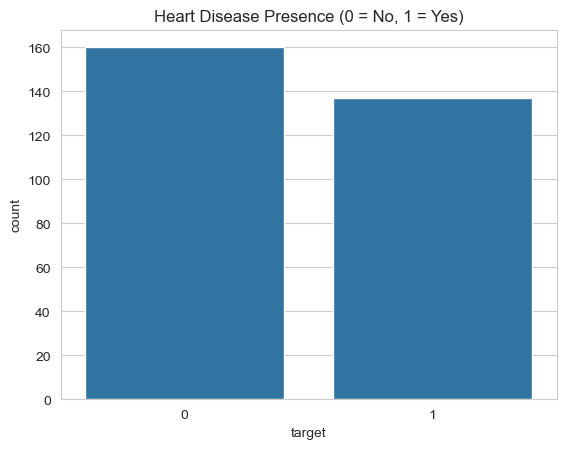

In [14]:
sns.countplot(data=df, x='target')
plt.title('Heart Disease Presence (0 = No, 1 = Yes)')
plt.show()

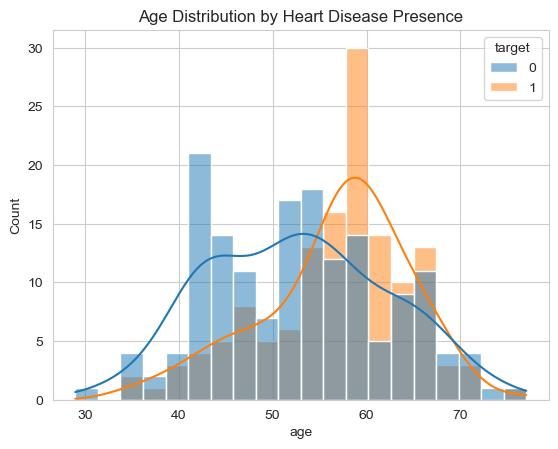

In [15]:
sns.histplot(data=df, x='age', hue='target', kde=True, bins=20)
plt.title('Age Distribution by Heart Disease Presence')
plt.show()

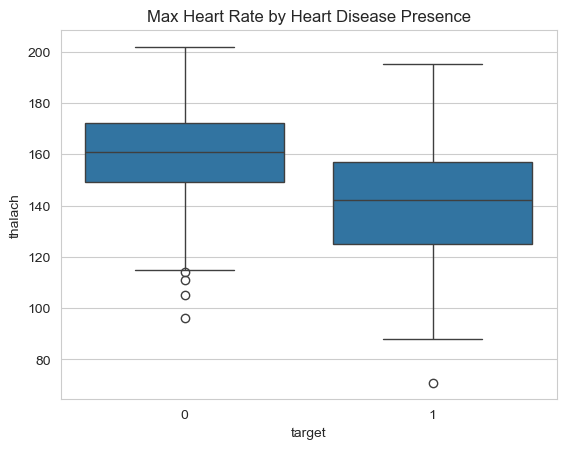

In [16]:
sns.boxplot(data=df, x='target', y='thalach')
plt.title('Max Heart Rate by Heart Disease Presence')
plt.show()

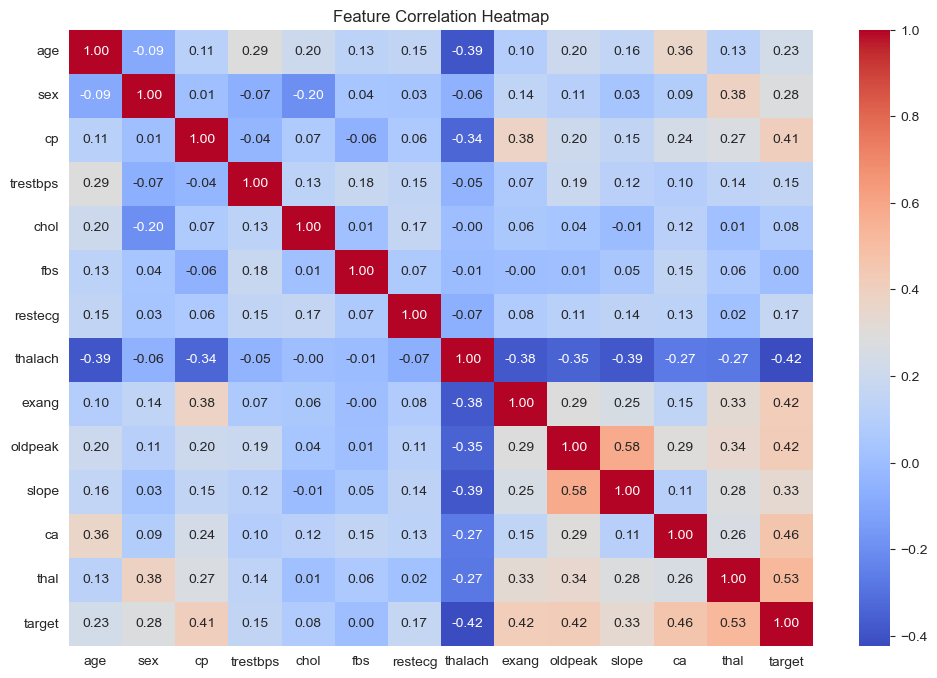

In [17]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()

## Feature Engineering & Train-Test Split

One-hot encoding categorical features (`cp`, `restecg`, `slope`, `thal`) splitting into train/test sets and scaling continuous features for logistic regression.

In [19]:
categorical_cols = ['cp', 'restecg', 'slope', 'thal']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
df_encoded.head()

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,target,cp_2.0,cp_3.0,cp_4.0,restecg_1.0,restecg_2.0,slope_2.0,slope_3.0,thal_6.0,thal_7.0
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,0,False,False,False,False,True,False,True,True,False
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,1,False,False,True,False,True,True,False,False,False
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,1,False,False,True,False,True,True,False,False,True
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,0,False,True,False,False,False,False,True,False,False
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,0,True,False,False,False,True,False,False,False,False


In [20]:
X = df_encoded.drop(columns=['target'])
y = df_encoded['target']

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(237, 18) (60, 18)


In [22]:
continuous_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test_scaled[continuous_cols] = scaler.transform(X_test[continuous_cols])

## Model Training & Evaluation

Fitting Logistic Regression and Decision Tree classifiers then comparing them on accuracy, confusion matrix, precision/recall and ROC-AUC with 5-fold cross-validation to confirm the result generalizes.

In [24]:
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

y_pred_log = log_reg.predict(X_test_scaled)

In [25]:
tree_clf = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_clf.fit(X_train, y_train)

y_pred_tree = tree_clf.predict(X_test)

In [26]:
print("Logistic Regression accuracy:", accuracy_score(y_test, y_pred_log))
print("Decision Tree accuracy:", accuracy_score(y_test, y_pred_tree))

Logistic Regression accuracy: 0.8666666666666667
Decision Tree accuracy: 0.7666666666666667


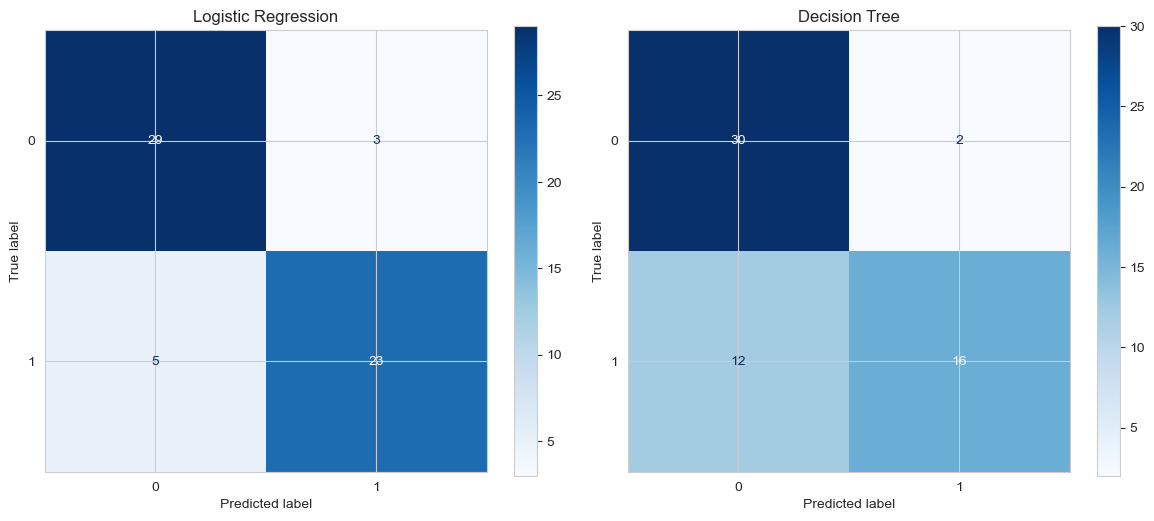

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_log)).plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Logistic Regression')

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_tree)).plot(ax=axes[1], cmap='Blues')
axes[1].set_title('Decision Tree')

plt.tight_layout()
plt.show()

In [28]:
print("Logistic Regression:\n", classification_report(y_test, y_pred_log))
print("Decision Tree:\n", classification_report(y_test, y_pred_tree))

Logistic Regression:
               precision    recall  f1-score   support

           0       0.85      0.91      0.88        32
           1       0.88      0.82      0.85        28

    accuracy                           0.87        60
   macro avg       0.87      0.86      0.87        60
weighted avg       0.87      0.87      0.87        60

Decision Tree:
               precision    recall  f1-score   support

           0       0.71      0.94      0.81        32
           1       0.89      0.57      0.70        28

    accuracy                           0.77        60
   macro avg       0.80      0.75      0.75        60
weighted avg       0.80      0.77      0.76        60



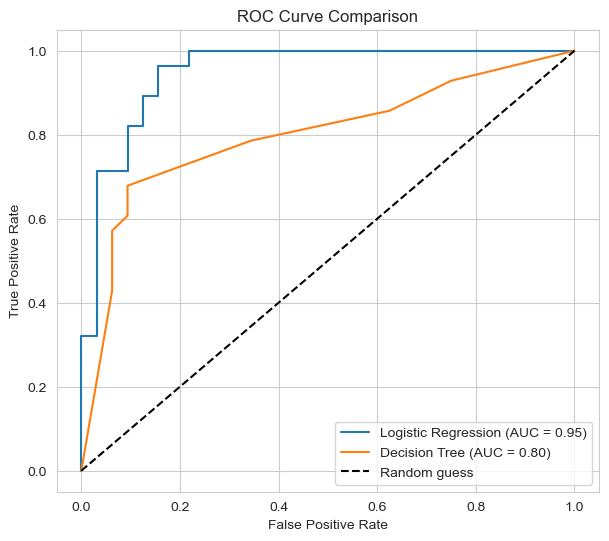

In [29]:
y_prob_log = log_reg.predict_proba(X_test_scaled)[:, 1]
y_prob_tree = tree_clf.predict_proba(X_test)[:, 1]

fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_tree, tpr_tree, _ = roc_curve(y_test, y_prob_tree)

plt.figure(figsize=(7, 6))
plt.plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_log):.2f})')
plt.plot(fpr_tree, tpr_tree, label=f'Decision Tree (AUC = {roc_auc_score(y_test, y_prob_tree):.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

## Feature Interpretation & Cross-Validation

Examining which features most strongly influence each model's predictions and validating the logistic regression result with 5-fold cross-validation to confirm it holds beyond a single train-test split.

In [31]:
coef_df = pd.DataFrame({
    'feature': X_train.columns,
    'coefficient': log_reg.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)

print(coef_df)

        feature  coefficient
17     thal_7.0     1.412715
11       cp_4.0     1.261975
1           sex     0.960132
8            ca     0.860104
14    slope_2.0     0.776763
6         exang     0.500164
7       oldpeak     0.493877
13  restecg_2.0     0.488258
10       cp_3.0    -0.482841
15    slope_3.0     0.468808
2      trestbps     0.355595
4           fbs    -0.333275
9        cp_2.0     0.292572
5       thalach    -0.257727
3          chol     0.217364
16     thal_6.0     0.142302
12  restecg_1.0     0.065655
0           age    -0.023393


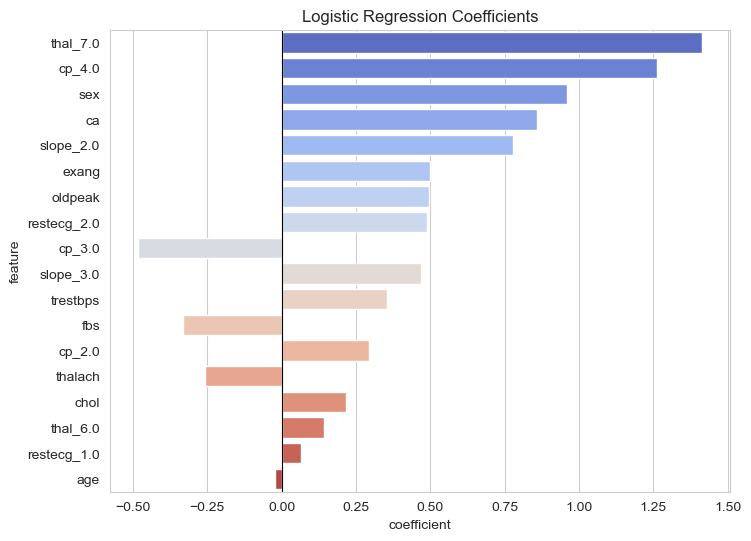

In [32]:
plt.figure(figsize=(8, 6))
sns.barplot(data=coef_df, x='coefficient', y='feature', hue='feature', palette='coolwarm', legend=False)
plt.title('Logistic Regression Coefficients')
plt.axvline(0, color='black', linewidth=0.8)
plt.show()

In [33]:
importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': tree_clf.feature_importances_
}).sort_values('importance', ascending=False)

print(importance_df)

        feature  importance
11       cp_4.0    0.392050
8            ca    0.206417
17     thal_7.0    0.132186
7       oldpeak    0.103199
14    slope_2.0    0.066326
2      trestbps    0.040316
5       thalach    0.034617
0           age    0.024889
6         exang    0.000000
1           sex    0.000000
10       cp_3.0    0.000000
4           fbs    0.000000
12  restecg_1.0    0.000000
13  restecg_2.0    0.000000
3          chol    0.000000
15    slope_3.0    0.000000
16     thal_6.0    0.000000
9        cp_2.0    0.000000


In [34]:
cv_scores = cross_val_score(log_reg, X_train_scaled, y_train, cv=5, scoring='roc_auc')
print("Cross-validated AUC scores:", cv_scores)
print("Mean AUC:", cv_scores.mean())

Cross-validated AUC scores: [0.96678322 0.93181818 0.90545455 0.84181818 0.78021978]
Mean AUC: 0.8852187812187813


## Summary & Key Findings

- Built an end-to-end classification pipeline on the UCI Cleveland Heart Disease dataset (297 patients after cleaning) comparing Logistic Regression with Decision Tree
- Logistic Regression outperformed the Decision Tree across every metric — notably AUC (0.95 vs 0.80) and recall on disease-positive cases (0.82 vs 0.57) the metric that matters most in a screening context
- Validated with 5-fold cross-validation giving a mean AUC of 0.885 a more reliable estimate than the single test-split score
- Both models independently converged on the same top predictors: `cp_4.0` (asymptomatic chest pain), `ca` (major vessels colored by fluoroscopy) and `thal_7.0` (reversible defect) — agreement across model types strengthens confidence these relationships are real

**Limitations:** Small sample size (297 patients) from a single hospital population collected in the late 1980s the results would need revalidation on more recent, more diverse data before any real-world application.